# Puntos y cajas: entrenamiento y evaluación

In [1]:
import random
from juego import Juego, MODELO, JUGADOR, SIMBOLOS, EXTREMOS

SEMILLA = 42
random.seed(SEMILLA)

## Acciones y estado

In [2]:
for accion, extremos in enumerate(EXTREMOS):
    print(f'Acción {accion:2}: puntos {extremos[0]}–{extremos[1]}')

juego = Juego(jugador_inicial=MODELO)
print(juego.representar())
print('Líneas libres:', juego.movimientos_validos())

Acción  0: puntos 0–1
Acción  1: puntos 1–2
Acción  2: puntos 3–4
Acción  3: puntos 4–5
Acción  4: puntos 6–7
Acción  5: puntos 7–8
Acción  6: puntos 0–3
Acción  7: puntos 1–4
Acción  8: puntos 2–5
Acción  9: puntos 3–6
Acción 10: puntos 4–7
Acción 11: puntos 5–8
 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M
Líneas libres: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


## Simulación de una partida aleatorio contra aleatorio

In [3]:
def elegir_accion_aleatoria(juego):
    return random.choice(juego.movimientos_validos())

def ejecutar_partida(jugador_inicial=None, mostrar=True):

    juego = Juego(jugador_inicial)
    if mostrar:
        print(juego.representar())
    while not juego.terminado():

        jugador = juego.obtener_turno()
        accion = elegir_accion_aleatoria(juego)
        resultado = juego.jugar(accion)
        if mostrar:
            print(f'\n{SIMBOLOS[jugador]} elige línea {accion}; '
                  f'captura {len(resultado["cajas_capturadas"])} caja(s).')
            print(juego.representar())
    return juego

In [4]:
partida = ejecutar_partida(jugador_inicial=MODELO)

 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M elige línea 10; captura 0 caja(s).
 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: J

J elige línea 1; captura 0 caja(s).
 +    0    + ------- + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M elige línea 0; captura 0 caja(s).
 + ------- + ------- + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: J

J elige línea 6; captura 0 caja(s).
 + ------- + ------- + 
 |         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M elige línea 5; captura 0 caja(s).
 + ------- + ------- + 
 |         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    + 

## Por qué ganar al azar no equivale necesariamente al 50 %

## Referencia experimental: 1.000 partidas aleatorias

In [5]:
cantidadPartidas = 1000

resultadosPartidas = {
    0: 0,
    MODELO: 0,
    JUGADOR: 0
}

for numeroPartida in range(cantidadPartidas):

    jugadorInicial = MODELO if numeroPartida % 2 == 0 else JUGADOR

    partida = Juego(jugadorInicial)

    cantidadMovimientosRealizados = 0

    while not partida.terminado():

        jugadorAntesDelMovimiento = partida.obtener_turno()

        accionAleatoria = elegir_accion_aleatoria(partida)

        resultadoMovimiento = partida.jugar(accionAleatoria)

        cantidadMovimientosRealizados += 1

        assert (
            len(partida.movimientos_validos())
            == 12 - cantidadMovimientosRealizados
        )

        if not partida.terminado():

            if resultadoMovimiento['cajas_capturadas']:

                assert partida.obtener_turno() == jugadorAntesDelMovimiento

            else:

                assert partida.obtener_turno() != jugadorAntesDelMovimiento

    assert cantidadMovimientosRealizados == 12

    assert sum(partida.puntajes().values()) == 4

    assert partida.obtener_turno() is None

    ganadorPartida = partida.ganador()

    resultadosPartidas[ganadorPartida] += 1

    estadoAntesDelIntentoInvalido = partida.obtener_estado()

    try:

        partida.jugar(0)

    except ValueError:

        pass

    else:

        raise AssertionError('Se permitió jugar tras el final')

    assert partida.obtener_estado() == estadoAntesDelIntentoInvalido

print(f'{cantidadPartidas} partidas verificadas.')

cantidadVictoriasModelo = resultadosPartidas[MODELO]
cantidadDerrotasModelo = resultadosPartidas[JUGADOR]
cantidadEmpates = resultadosPartidas[0]

porcentajeVictoriasModelo = cantidadVictoriasModelo / cantidadPartidas * 100
porcentajeDerrotasModelo = cantidadDerrotasModelo / cantidadPartidas * 100
porcentajeEmpates = cantidadEmpates / cantidadPartidas * 100

print(
    f'Victorias M: {cantidadVictoriasModelo} '
    f'({porcentajeVictoriasModelo:.2f}%)'
)
print(
    f'Derrotas M: {cantidadDerrotasModelo} '
    f'({porcentajeDerrotasModelo:.2f}%)'
)
print(
    f'Empates: {cantidadEmpates} '
    f'({porcentajeEmpates:.2f}%)'
)

recompensaMediaAleatoria = (cantidadVictoriasModelo + 0.5 * cantidadEmpates) / cantidadPartidas

1000 partidas verificadas.
Victorias M: 427 (42.70%)
Derrotas M: 427 (42.70%)
Empates: 146 (14.60%)


## Agente tabular

### Qué contiene realmente el modelo

### Cómo decide una acción

### Cómo aprende después de una partida

In [6]:
class Agente:
    def __init__(self, alfa=0.1, epsilon=0.2):
        if not 0 < alfa <= 1 or not 0 <= epsilon <= 1:
            raise ValueError('Parámetros fuera de rango')

        self.alfa = alfa

        self.epsilon = epsilon

        self.valores = {}

        self.historial = []

    def elegir_accion(self, juego, rng, explorar=True):
        acciones = juego.movimientos_validos()
        if not acciones or juego.obtener_turno() != MODELO:
            raise ValueError('El agente solo actúa durante el turno de M')

        if explorar and rng.random() < self.epsilon:
            return rng.choice(acciones)

        mejores = []
        mejor_valor = float('-inf')
        for accion in acciones:

            copia = juego.copiar()

            copia.jugar(accion)

            valor = self.valores.get(copia.obtener_estado(), 0.5)
            if valor > mejor_valor:
                mejor_valor = valor

                mejores = [accion]
            elif valor == mejor_valor:

                mejores.append(accion)

        return rng.choice(mejores)

    def registrar(self, juego):

        self.historial.append(juego.obtener_estado())

    def aprender(self, recompensa):

        objetivo = recompensa

        for estado in reversed(self.historial):

            anterior = self.valores.get(estado, 0.5)

            self.valores[estado] = anterior + self.alfa * (objetivo - anterior)

            objetivo = self.valores[estado]

        self.historial.clear()

def recompensa_final(juego):
    ganador = juego.ganador()
    if ganador is None:
        raise ValueError('La partida debe haber terminado')

    return 1.0 if ganador == MODELO else 0.5 if ganador == 0 else 0.0

## Partidas y evaluación

### Una función de partida, dos modos

### Cómo leer las métricas

In [7]:
def partida_agente(agente, inicial, rng, entrenar=False, mostrar=False):
    juego = Juego(inicial)
    if entrenar:

        agente.historial.clear()
    if mostrar:
        print(juego.representar())
    while not juego.terminado():

        jugador = juego.obtener_turno()
        if jugador == MODELO:

            accion = agente.elegir_accion(juego, rng, explorar=entrenar)
        else:

            accion = rng.choice(juego.movimientos_validos())
        resultado = juego.jugar(accion)
        if entrenar:

            agente.registrar(juego)
        if mostrar:
            print(f'\n{SIMBOLOS[jugador]} coloca línea {accion}; '
                  f'captura {len(resultado["cajas_capturadas"])} caja(s): '
                  f'{resultado["cajas_capturadas"]}')
            print(juego.representar())
    if entrenar:

        agente.aprender(recompensa_final(juego))
    return juego

def evaluar(agente, partidas=1000):
    if partidas < 2 or partidas % 2:
        raise ValueError('Usa un número par de partidas, al menos 2')

    rng = random.Random(SEMILLA)
    conteo = {0: 0, MODELO: 0, JUGADOR: 0}

    por_inicio = {MODELO: [0, 0], JUGADOR: [0, 0]}
    cajas_m = diferencia = 0
    for numero in range(partidas):
        inicial = MODELO if numero % 2 == 0 else JUGADOR
        juego = partida_agente(agente, inicial, rng)
        ganador = juego.ganador()
        conteo[ganador] += 1
        por_inicio[inicial][0] += ganador == MODELO
        por_inicio[inicial][1] += 1
        puntos = juego.puntajes()
        cajas_m += puntos[MODELO]

        diferencia += puntos[MODELO] - puntos[JUGADOR]
    return {
        'victorias_pct': 100 * conteo[MODELO] / partidas,
        'empates_pct': 100 * conteo[0] / partidas,
        'derrotas_pct': 100 * conteo[JUGADOR] / partidas,
        'cajas_m': cajas_m / partidas,
        'diferencia_cajas': diferencia / partidas,
        'recompensa_media': (conteo[MODELO] + 0.5 * conteo[0]) / partidas,
        'victorias_inicia_m_pct': 100 * por_inicio[MODELO][0] / por_inicio[MODELO][1],
        'victorias_inicia_j_pct': 100 * por_inicio[JUGADOR][0] / por_inicio[JUGADOR][1],
    }

## Experimento: influencia de epsilon

### Qué significa cada cantidad

In [8]:
from time import perf_counter

ALFA = 0.1

EPSILONS = [0.0, 0.1, 0.2, 0.4]

EPISODIOS = 30000

INTERVALO = 1000

PARTIDAS_EVALUACION = 1000

agentes = {}
metricas = []
inicio = perf_counter()
for epsilon in EPSILONS:

    candidato = Agente(ALFA, epsilon)

    rng_entrenamiento = random.Random(SEMILLA)

    for episodio in range(EPISODIOS + 1):
        if episodio > 0:

            inicial = MODELO if (episodio - 1) % 2 == 0 else JUGADOR
            partida_agente(candidato, inicial, rng_entrenamiento, entrenar=True)
        if episodio % INTERVALO == 0:

            antes = candidato.valores.copy()
            fila = evaluar(candidato, PARTIDAS_EVALUACION)
            assert candidato.valores == antes and not candidato.historial

            fila.update(epsilon=epsilon, episodios=episodio)
            metricas.append(fila)

    agentes[epsilon] = candidato
    print(f"epsilon={epsilon:.1f}: victorias={fila['victorias_pct']:.1f}%, "
          f"empates={fila['empates_pct']:.1f}%, derrotas={fila['derrotas_pct']:.1f}%")
print(f'Tiempo total: {perf_counter() - inicio:.1f} segundos')

epsilon=0.0: victorias=79.3%, empates=14.4%, derrotas=6.3%
epsilon=0.1: victorias=83.3%, empates=13.2%, derrotas=3.5%
epsilon=0.2: victorias=84.7%, empates=11.0%, derrotas=4.3%
epsilon=0.4: victorias=84.1%, empates=11.0%, derrotas=4.9%
Tiempo total: 346.1 segundos


## Comparación y elección de epsilon

In [9]:
claves = ['victorias_pct', 'empates_pct', 'derrotas_pct', 'recompensa_media',
          'victorias_inicia_m_pct', 'victorias_inicia_j_pct']
resumen = [m for m in metricas if m['episodios'] == EPISODIOS]

print('Configuración      V%      E%      D%    Recompensa   V% inicia M   V% inicia J')
print(f'Aleatorio (1000)  {porcentajeVictoriasModelo:6.2f}  {porcentajeEmpates:6.2f}  '
      f'{porcentajeDerrotasModelo:6.2f}     {recompensaMediaAleatoria:.3f}             —             —')
for r in resumen:
    print(f"epsilon={r['epsilon']:.1f}       {r['victorias_pct']:6.2f}  {r['empates_pct']:6.2f}  "
          f"{r['derrotas_pct']:6.2f}     {r['recompensa_media']:.3f}        "
          f"{r['victorias_inicia_m_pct']:6.2f}        {r['victorias_inicia_j_pct']:6.2f}")

EPSILON = max(resumen, key=lambda r: r['victorias_pct'])['epsilon']

agente = agentes[EPSILON]
print(f'\nElegido: epsilon={EPSILON}, después de {EPISODIOS} partidas.')

Configuración      V%      E%      D%    Recompensa   V% inicia M   V% inicia J
Aleatorio (1000)   42.70   14.60   42.70     0.500             —             —
epsilon=0.0        79.30   14.40    6.30     0.865         91.20         67.40
epsilon=0.1        83.30   13.20    3.50     0.899         89.20         77.40
epsilon=0.2        84.70   11.00    4.30     0.902         92.80         76.60
epsilon=0.4        84.10   11.00    4.90     0.896         91.20         77.00

Elegido: epsilon=0.2, después de 30000 partidas.


## Curvas de aprendizaje

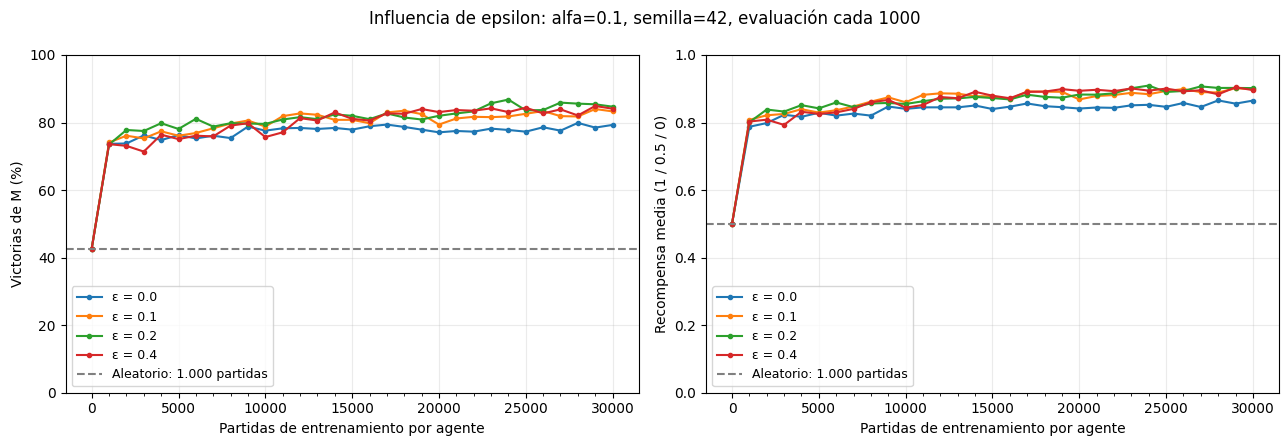

In [10]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for epsilon in EPSILONS:
    filas = [m for m in metricas if m['epsilon'] == epsilon]
    x = [m['episodios'] for m in filas]
    ejes[0].plot(x, [m['victorias_pct'] for m in filas], marker='o', markersize=3, label=f'ε = {epsilon}')
    ejes[1].plot(x, [m['recompensa_media'] for m in filas], marker='o', markersize=3, label=f'ε = {epsilon}')

ejes[0].axhline(porcentajeVictoriasModelo, color='gray', linestyle='--', label='Aleatorio: 1.000 partidas')
ejes[1].axhline(recompensaMediaAleatoria, color='gray', linestyle='--', label='Aleatorio: 1.000 partidas')
ejes[0].set_ylabel('Victorias de M (%)')
ejes[1].set_ylabel('Recompensa media (1 / 0.5 / 0)')
ejes[0].set_ylim(0, 100)
ejes[1].set_ylim(0, 1)
for eje in ejes:
    eje.set_xlabel('Partidas de entrenamiento por agente')
    eje.set_xticks(range(0, EPISODIOS + 1, 5000))
    eje.set_xticks(range(0, EPISODIOS + 1, INTERVALO), minor=True)
    eje.grid(alpha=0.25)
    eje.legend(fontsize=9)
fig.suptitle(f'Influencia de epsilon: alfa={ALFA}, semilla={SEMILLA}, evaluación cada {INTERVALO}')
fig.tight_layout()
plt.show()

## Evaluación ampliada del agente elegido

In [11]:
antes = agente.valores.copy()

final = evaluar(agente, partidas=5000)

base_final = evaluar(Agente(), partidas=5000)
assert agente.valores == antes and not agente.historial
print('Métrica                       Aleatorio    Entrenado')
for clave in claves:
    print(f'{clave:29} {base_final[clave]:9.3f}    {final[clave]:9.3f}')

Métrica                       Aleatorio    Entrenado
victorias_pct                    41.880       84.620
empates_pct                      15.680       10.660
derrotas_pct                     42.440        4.720
recompensa_media                  0.497        0.899
victorias_inicia_m_pct           42.320       93.320
victorias_inicia_j_pct           41.440       75.920


### Interpretación

## Guardar y cargar el modelo elegido

In [12]:
import pickle
from pathlib import Path

Path('modelos').mkdir(exist_ok=True)

datos_modelo = {
    'valores': agente.valores,
    'alfa': ALFA,
    'epsilon': EPSILON,
    'semilla': SEMILLA,
    'episodios': EPISODIOS,
    'estado': 'lineas_cajas_turno',
    'recompensas': (1, 0.5, 0),
}

with open('modelos/agente.pickle', 'wb') as archivo:
    pickle.dump(datos_modelo, archivo)

with open('modelos/agente.pickle', 'rb') as archivo:
    datos = pickle.load(archivo)

agente_cargado = Agente(datos['alfa'], datos['epsilon'])

agente_cargado.valores = datos['valores']

assert agente_cargado.valores == agente.valores
print('Modelo elegido guardado y recargado correctamente: modelos/agente.pickle')

Modelo elegido guardado y recargado correctamente: modelos/agente.pickle


## Demostración completa: modelo cargado contra aleatorio

In [13]:
rng_demostracion = random.Random(SEMILLA)

demostracion = partida_agente(
    agente=agente_cargado,
    inicial=MODELO,
    rng=rng_demostracion,
    mostrar=True,
)

assert demostracion.terminado()
assert not demostracion.movimientos_validos()

 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M coloca línea 5; captura 0 caja(s): ()
 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    + ------- + 
M: 0 | J: 0
Turno: J

J coloca línea 0; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    + ------- + 
M: 0 | J: 0
Turno: M

M coloca línea 10; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    + ------- + 
M: 0 | J: 0
Turno: J

J coloca línea 4; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 + ------- + ------- + 
M: 0 | J: 0
Turno: M

M coloca línea 11; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |    